# 02 — Entrenamiento del Juez Evaluador (Transfer Learning con AST Preentrenado)

**Proyecto Final — Inteligencia Artificial II**  
**Alumno:** Enzo Palau | **Legajo:** 13686 | **Universidad:** UNCuyo  

---

## Objetivo

Entrenar y comparar modelos de clasificación de familias de instrumentos sobre espectrogramas mel 128×128 del dataset NSynth, integrando:
1. **Línea Base Convolucional:** `CNN-Simple` (4,932 parámetros) entrenada **desde cero (sin preentrenamiento)**.
2. **Transfer Learning con AST de Hugging Face:** `MIT/ast-finetuned-audioset-10-10-0.4593` (~87 M parámetros) preentrenado en AudioSet e ImageNet. Se evalúan dos configuraciones de transferencia:
   - **AST-Pretrained (Head-Only):** Backbone congelado, solo se entrena la cabeza clasificadora a 4 clases.
   - **AST-Pretrained (Full Fine-Tuning):** Todas las capas descongeladas con learning rate suave (`3e-5`) y warmup.

Este notebook cumple de manera exacta y rigurosa con lo propuesto en el **anteproyecto**:
> *"Línea base: una CNN pequeña"* y *"El evaluador usa transferencia de aprendizaje a partir de un modelo preentrenado."*

---
## 1. Configuración del entorno

### ¿Qué se hace a continuación?
Se importan todas las librerías necesarias y se configura el entorno de ejecución: se detecta automáticamente si el notebook corre en Kaggle, Google Colab o localmente, y se fijan los paths de entrada y salida correspondientes. Se establece la semilla global `SEED=1` para garantizar reproducibilidad total en NumPy, PyTorch y Python built-ins.

### ¿Por qué se hace?
La detección automática del entorno permite que el mismo notebook se ejecute sin modificaciones en Kaggle (donde los datos están en `/kaggle/input/`) y localmente (donde están en `./data_processed/processed/`). Fijar la semilla aleatoria es una buena práctica científica: asegura que los resultados sean reproducibles y comparables entre ejecuciones.

In [1]:
import os
import sys
import random
import warnings
import json
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split

# Hugging Face Transformers para el modelo AST preentrenado
try:
    from transformers import ASTForAudioClassification
except ImportError:
    print('[ADVERTENCIA] transformers no instalado. Instalando...')
    os.system('pip install -q transformers')
    from transformers import ASTForAudioClassification

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
)

try:
    from tqdm.notebook import tqdm
except ImportError:
    from tqdm import tqdm

warnings.filterwarnings('ignore')

# ── Semilla global ──────────────────────────────────────────────────────────
SEED = 1
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

# ── Detección de entorno ────────────────────────────────────────────────────
IN_KAGGLE = os.environ.get('KAGGLE_KERNEL_RUN_TYPE') is not None
IN_COLAB  = 'google.colab' in sys.modules

if IN_KAGGLE:
    _candidatos_kaggle = [
        Path('/kaggle/input/datasets/enzopalau/nsynth-processed-palau'),
        Path('/kaggle/input/nsynth-processed-palau'),
        Path('/kaggle/input/nsynth-processed'),
    ]
    DATA_DIR = next(
        (p for p in _candidatos_kaggle if any(p.glob('*.npz'))),
        _candidatos_kaggle[0]
    )
    OUTPUT_DIR = Path('/kaggle/working/juez_output')
    print('[INFO] Entorno detectado: Kaggle')
elif IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR   = Path('/content/drive/MyDrive/IA2_Proyecto_Instrumentos/processed')
    OUTPUT_DIR = Path('/content/drive/MyDrive/IA2_Proyecto_Instrumentos/juez_output')
    print('[INFO] Entorno detectado: Google Colab')
else:
    DATA_DIR   = Path('./data_processed/processed')
    OUTPUT_DIR = Path('./juez_output')
    print('[INFO] Entorno detectado: local')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'[INFO] DATA_DIR   = {DATA_DIR}')
print(f'[INFO] OUTPUT_DIR = {OUTPUT_DIR}')

[INFO] Entorno detectado: Kaggle
[INFO] DATA_DIR   = /kaggle/input/datasets/enzopalau/nsynth-processed-palau
[INFO] OUTPUT_DIR = /kaggle/working/juez_output


---
## 2. Detección de hardware

### ¿Qué se hace a continuación?
Se detecta automáticamente si hay una GPU CUDA disponible. Si la hay, se usa; en caso contrario se cae a CPU. Se imprime información del dispositivo para verificación.

### ¿Por qué se hace?
El entrenamiento de redes neuronales es significativamente más rápido en GPU. La detección automática hace que el código sea portátil y no requiera modificaciones manuales al cambiar de entorno.

In [2]:
# ── Dispositivo de cómputo ──────────────────────────────────────────────────
if torch.cuda.is_available():
    device = torch.device('cuda')
    gpu_name = torch.cuda.get_device_name(0)
    gpu_mem  = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'[INFO] GPU disponible: {gpu_name} ({gpu_mem:.1f} GB VRAM)')
else:
    device = torch.device('cpu')
    print('[ADVERTENCIA] No se detectó GPU. Se usará CPU (entrenamiento lento).')

print(f'[INFO] Dispositivo seleccionado: {device}')

[INFO] GPU disponible: Tesla T4 (15.6 GB VRAM)
[INFO] Dispositivo seleccionado: cuda


---
## 3. Carga de datos

### ¿Qué se hace a continuación?
Se cargan los archivos `.npz` generados en el notebook anterior (`01_preprocesamiento.ipynb`). Cada split (train/val/test) tiene un archivo con cuatro arrays: `mels` (espectrogramas mel 128×128), `families` (etiquetas de familia 0-3), `pitches` (MIDI 36-84) e `instruments` (ID de instrumento). Se normalizan los espectrogramas al rango `[-1, 1]` si aun no lo están, y se convierten a tensores PyTorch.

### ¿Por qué se hace?
Cargar todos los datos en RAM como `TensorDataset` es eficiente para datasets de tamaño moderado (NSynth filtrado). Evita el overhead de I/O durante el entrenamiento y simplifica el pipeline. La normalización a `[-1, 1]` asegura que las activaciones iniciales de la red estén en un rango razonable, lo que mejora la estabilidad del entrenamiento.

In [3]:
# ── Carga de los archivos .npz ───────────────────────────────────────────────
FAMILY_NAMES = ['brass', 'guitar', 'keyboard', 'string']
NUM_CLASSES  = len(FAMILY_NAMES)

def cargar_split(nombre_split: str):
    """Carga un split del dataset desde disco y devuelve tensores PyTorch.
    Prueba múltiples convenciones de nombre para compatibilidad entre entornos.
    El notebook 01 genera: nsynth_processed_{split}.npz  (split = train/valid/test)
    """
    # 'val' en este notebook -> 'valid' en los archivos del notebook 01
    alias = {'val': 'valid'}
    split_real = alias.get(nombre_split, nombre_split)

    # Convenciones de nombre a probar, en orden de prioridad
    candidatos = [
        DATA_DIR / f'nsynth_processed_{split_real}.npz',   # nombre real del notebook 01
        DATA_DIR / f'nsynth_processed_{nombre_split}.npz', # por si se guardó sin alias
        DATA_DIR / f'{split_real}.npz',
        DATA_DIR / f'{nombre_split}.npz',
        DATA_DIR / f'nsynth_{split_real}.npz',
        DATA_DIR / f'nsynth_{nombre_split}.npz',
    ]

    ruta = next((p for p in candidatos if p.exists()), None)
    if ruta is None:
        intentados = '\n  '.join(str(p) for p in candidatos)
        raise FileNotFoundError(
            f'[ERROR] No se encontró el split "{nombre_split}".\n'
            f'  Archivos buscados:\n  {intentados}\n'
            f'  Archivos presentes en DATA_DIR:\n  '
            + '\n  '.join(str(p) for p in DATA_DIR.glob('*.npz'))
        )

    print(f'[INFO] Cargando: {ruta.name}')

    datos = np.load(ruta)
    mels     = datos['mels'].astype(np.float32)      # (N, 128, 128)
    familias = datos['families'].astype(np.int64)    # (N,)

    # Verificar rango; normalizar a [-1, 1] si es necesario
    vmin, vmax = mels.min(), mels.max()
    if vmax > 1.01 or vmin < -1.01:
        print(f'[ADVERTENCIA] {nombre_split}: valores fuera de [-1,1] '
              f'(min={vmin:.2f}, max={vmax:.2f}). Renormalizando...')
        mels = (mels - vmin) / (vmax - vmin + 1e-8) * 2 - 1

    # Agregar canal: (N, 1, 128, 128)
    # Soportar ambas shapes: (N,128,128) y (N,1,128,128)
    if mels.ndim == 3:
        mels_t = torch.from_numpy(mels).unsqueeze(1)  # (N,128,128) -> (N,1,128,128)
    else:
        mels_t = torch.from_numpy(mels)               # ya viene (N,1,128,128)
    fam_t  = torch.from_numpy(familias)

    print(f'[INFO] Split "{nombre_split}": {len(mels_t)} muestras | '
          f'shape={tuple(mels_t.shape)} | '
          f'clases={np.bincount(familias).tolist()}')
    return mels_t, fam_t


# Cargar los tres splits
X_train, y_train = cargar_split('train')
X_val,   y_val   = cargar_split('val')
X_test,  y_test  = cargar_split('test')

print(f'\n[INFO] Total muestras: '
      f'train={len(X_train)}, val={len(X_val)}, test={len(X_test)}')

[INFO] Cargando: nsynth_processed_train.npz
[INFO] Split "train": 18000 muestras | shape=(18000, 1, 128, 128) | clases=[4500, 4500, 4500, 4500]
[INFO] Cargando: nsynth_processed_valid.npz
[INFO] Split "val": 2297 muestras | shape=(2297, 1, 128, 128) | clases=[704, 827, 170, 596]
[INFO] Cargando: nsynth_processed_test.npz
[INFO] Split "test": 771 muestras | shape=(771, 1, 128, 128) | clases=[201, 271, 75, 224]

[INFO] Total muestras: train=18000, val=2297, test=771


---
## 4. Creación de DataLoaders

### ¿Qué se hace a continuación?
Se crean objetos `TensorDataset` y `DataLoader` para cada split. Los DataLoaders de entrenamiento mezclan los datos en cada epoch (`shuffle=True`); los de validación y test no, para mantener el orden. Se define una función helper `crear_loaders` que acepta el tamaño de batch como parámetro, ya que cada modelo usará su propio `batch_size`.

### ¿Por qué se hace?
`TensorDataset` permite que PyTorch itere sobre los datos de forma eficiente. El shuffle en train evita que la red memorice el orden de las muestras. El `num_workers=0` asegura compatibilidad en todos los entornos (Kaggle, Colab, local) sin problemas de multiproceso.

In [4]:
# ── Datasets ─────────────────────────────────────────────────────────────────
ds_train = TensorDataset(X_train, y_train)
ds_val   = TensorDataset(X_val,   y_val)
ds_test  = TensorDataset(X_test,  y_test)

def crear_loaders(batch_size: int, seed: int = SEED):
    """Crea DataLoaders con el batch_size especificado y shuffling determinista."""
    gen = torch.Generator()
    gen.manual_seed(seed)
    loader_train = DataLoader(
        ds_train, batch_size=batch_size,
        shuffle=True, generator=gen, num_workers=0, pin_memory=(device.type == 'cuda')
    )
    loader_val = DataLoader(
        ds_val, batch_size=batch_size * 2,
        shuffle=False, num_workers=0, pin_memory=(device.type == 'cuda')
    )
    loader_test = DataLoader(
        ds_test, batch_size=batch_size * 2,
        shuffle=False, num_workers=0, pin_memory=(device.type == 'cuda')
    )
    return loader_train, loader_val, loader_test

print('[INFO] DataLoaders listos. '
      'Se instanciarán con el batch_size de cada modelo durante el entrenamiento.')

[INFO] DataLoaders listos. Se instanciarán con el batch_size de cada modelo durante el entrenamiento.


---
## 5. Visualización de muestras del dataset

### ¿Qué se hace a continuación?
Se muestran 8 espectrogramas mel del conjunto de entrenamiento (2 por familia) para verificar visualmente que los datos se cargaron correctamente. Se usa `matplotlib` con un mapa de colores `magma` que resalta la estructura espectral.

### ¿Por qué se hace?
La inspección visual de los datos es un paso de sanity-check fundamental. Permite detectar errores de carga, permutaciones incorrectas de ejes, o valores atípicos antes de invertir tiempo en el entrenamiento.

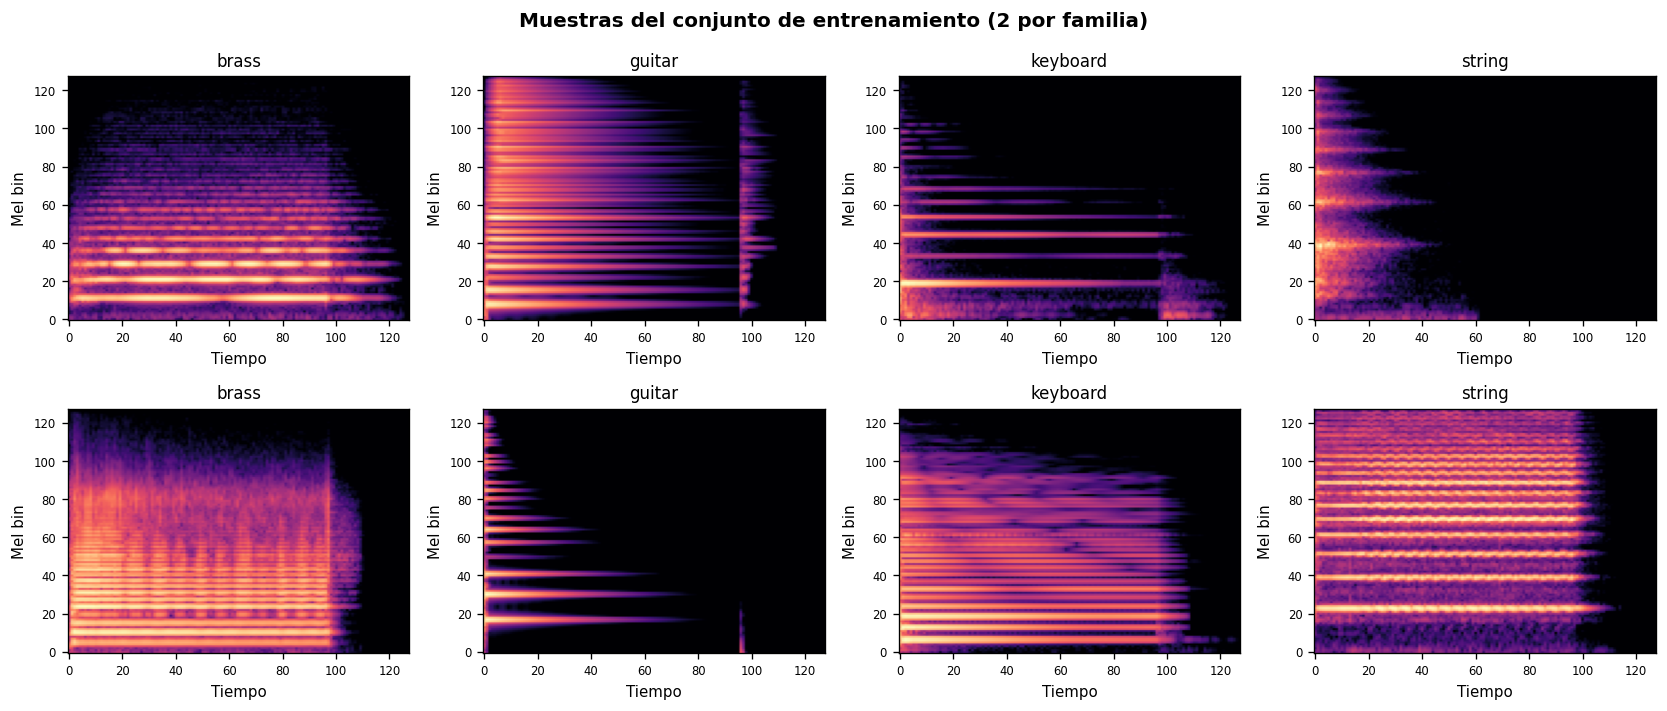

[INFO] Figura de muestras guardada.


In [5]:
# ── Sanity-check visual ───────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(14, 6), dpi=120)
fig.suptitle('Muestras del conjunto de entrenamiento (2 por familia)',
             fontsize=12, fontweight='bold')

for col, nombre_familia in enumerate(FAMILY_NAMES):
    # Obtener índices de esta familia
    idx_familia = (y_train == col).nonzero(as_tuple=True)[0]
    for fila in range(2):
        idx = idx_familia[fila].item()
        mel = X_train[idx].squeeze().numpy()   # (128, 128)
        ax  = axes[fila, col]
        im  = ax.imshow(mel, aspect='auto', origin='lower',
                        cmap='magma', vmin=-1, vmax=1)
        ax.set_title(f'{nombre_familia}', fontsize=10)
        ax.set_xlabel('Tiempo', fontsize=9)
        ax.set_ylabel('Mel bin', fontsize=9)
        ax.tick_params(labelsize=7)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'muestras_dataset.png', dpi=120, bbox_inches='tight')
plt.show()
print('[INFO] Figura de muestras guardada.')

---
## 6. Definición del modelo CNN Simple (Baseline Liviano)

### ¿Qué se hace a continuación?
Se define la clase `CNNSimple`, una arquitectura convolucional clásica de **2 bloques** (Conv2D + BatchNorm + ReLU + MaxPool2d). La red opera sobre espectrogramas de **1 canal** y predice las **4 clases** de familias de instrumentos.

### ¿Por qué se hace?
En el anteproyecto se propuso como línea base para el evaluador: *"un clasificador sencillo (por ejemplo, una CNN pequeña o regresión logística sobre características simples)"*.
A diferencia de arquitecturas masivas prediseñadas como ResNet-18 (que posee más de 11 millones de parámetros), esta `CNNSimple` cuenta con aproximadamente **4,932 parámetros **. Esto proporciona un **baseline**: una CNN compacta que sirve de punto de comparación frente a las arquitecturas basadas en Transformers (AST).

In [6]:
class CNNSimple(nn.Module):
    """
    Baseline mínimo de 2 bloques convolucionales para espectrogramas 128x128.
    """

    def __init__(self, in_channels: int = 1, num_classes: int = 4):
        super().__init__()
        self.features = nn.Sequential(
            # Bloque 1: 128x128 -> 64x64
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),

            # Bloque 2: 64x64 -> 64x64 (el GAP reduce a 1x1 en forward)
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )
        # Proyección directa sin capa oculta ni Dropout
        self.classifier = nn.Linear(32, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x).mean(dim=(-2, -1))  # Global Avg Pool (B, 32)
        return self.classifier(x)


def contar_parametros(modelo: nn.Module) -> int:
    """Cuenta el número de parámetros entrenables del modelo."""
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)


# Verificación de la arquitectura
cnn_test = CNNSimple(in_channels=1, num_classes=NUM_CLASSES)
dummy    = torch.zeros(2, 1, 128, 128)   # batch=2, canal=1, 128x128
out      = cnn_test(dummy)
params   = contar_parametros(cnn_test)

print(f'[INFO] CNNSimple — output shape: {tuple(out.shape)}')
print(f'[INFO] CNNSimple — parámetros entrenables: {params:,} ({params/1e6:.2f} M)')
del cnn_test, dummy, out

[INFO] CNNSimple — output shape: (2, 4)
[INFO] CNNSimple — parámetros entrenables: 4,932 (0.00 M)


---
## 7. Definición del modelo AST Preentrenado (Hugging Face Transfer Learning)

### ¿Qué se hace a continuación?
Se define la clase adaptadora `ASTPretrainedWrapper` sobre el modelo oficial `MIT/ast-finetuned-audioset-10-10-0.4593` de Hugging Face.
El wrapper realiza internamente:
1. Recibe un tensor con forma `(B, 1, 128_freq, 128_time)` procedente del dataset del proyecto.
2. Transpone los ejes para que el orden sea `(B, 1, 128_time, 128_freq)`.
3. Interpola linealmente la dimensión temporal de 128 a **1024 pasos** mediante `F.interpolate`, alcanzando exactamente la forma `(B, 1024, 128)` que espera la arquitectura original del AST.
4. Pasa los datos por el transformer preentrenado y extrae los logits correspondientes a las **4 familias de instrumentos**.

### ¿Por qué se hace?
El AST original fue preentrenado con más de 2 millones de audios de AudioSet y 1.3 millones de imágenes de ImageNet, contando con **~87 millones de parámetros**. Utilizar Transfer Learning cumple con la metodología explicitada en el anteproyecto. Permite evaluar si las representaciones acústicas ricas aprendidas en AudioSet superan a una CNN entrenada puramente desde cero sobre el subconjunto acotado de notas aisladas.

In [7]:
class ASTPretrainedWrapper(nn.Module):
    """
    Wrapper de Audio Spectrogram Transformer (AST) preentrenado en AudioSet.
    Adapta la entrada mel 128x128 del proyecto a (max_length, 128) mediante
    interpolación bilineal suave sobre la dimensión temporal e interpolación
    de los position embeddings preentrenados cuando max_length != 1024.
    Permite además extraer embeddings pre-clasificador (pooling de 768 dims).
    Usa SDPA (Scaled Dot-Product Attention) si está soportado para máxima velocidad.
    """

    def __init__(self, num_classes: int = 4, freeze_backbone: bool = False, max_length: int = 1024):
        super().__init__()
        model_id = 'MIT/ast-finetuned-audioset-10-10-0.4593'
        self.max_length = max_length
        kw = {} if max_length == 1024 else {'max_length': max_length}

        # Intentar cargar con SDPA (Scaled Dot-Product Attention nativo de PyTorch)
        try:
            self.ast = ASTForAudioClassification.from_pretrained(
                model_id,
                num_labels=num_classes,
                ignore_mismatched_sizes=True,
                attn_implementation='sdpa',
                **kw
            )
            print(f'[INFO] AST cargado (max_length={max_length}) con SDPA activado.')
        except Exception as e:
            self.ast = ASTForAudioClassification.from_pretrained(
                model_id,
                num_labels=num_classes,
                ignore_mismatched_sizes=True,
                **kw
            )
            print(f'[INFO] AST cargado (max_length={max_length}) con atención estándar ({e}).')

        self.ast.config.problem_type = 'single_label_classification'

        if max_length != 1024:
            self._adaptar_pos_embed(model_id)

        self.freeze_backbone = freeze_backbone
        if freeze_backbone:
            for name, param in self.ast.named_parameters():
                if 'classifier' not in name:
                    param.requires_grad = False

    def _adaptar_pos_embed(self, model_id: str):
        """Interpola los position embeddings preentrenados a la nueva longitud temporal."""
        base = ASTForAudioClassification.from_pretrained(model_id)
        emb_o = base.audio_spectrogram_transformer.embeddings
        emb_n = self.ast.audio_spectrogram_transformer.embeddings
        f_o, t_o = emb_o.get_shape(base.config)
        f_n, t_n = emb_n.get_shape(self.ast.config)
        pe   = emb_o.position_embeddings.data                      # (1, 2+f*t, 768)
        grid = pe[:, 2:].reshape(1, f_o, t_o, -1).permute(0, 3, 1, 2)
        grid = F.interpolate(grid, size=(f_n, t_n), mode='bilinear', align_corners=False)
        grid = grid.permute(0, 2, 3, 1).reshape(1, f_n * t_n, -1)
        emb_n.position_embeddings.data.copy_(torch.cat([pe[:, :2], grid], dim=1))
        del base

    def _prep(self, x: torch.Tensor) -> torch.Tensor:
        x = x.transpose(-1, -2)
        x = F.interpolate(x, size=(self.max_length, 128), mode='bilinear', align_corners=False)
        return x.squeeze(1)

    def forward_features(self, x: torch.Tensor) -> torch.Tensor:
        """Extrae el vector de características de 768 dimensiones del transformer."""
        outputs = self.ast.audio_spectrogram_transformer(self._prep(x))
        # El pooling estándar en AST toma el promedio del CLS y distillation token
        return (outputs[0][:, 0] + outputs[0][:, 1]) / 2.0

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.ast(self._prep(x)).logits


# Verificación de la arquitectura AST Preentrenada
print('[INFO] Descargando/Verificando AST preentrenado de Hugging Face...')
ast_test = ASTPretrainedWrapper(num_classes=NUM_CLASSES, freeze_backbone=True, max_length=1024)
dummy = torch.zeros(2, 1, 128, 128)
out = ast_test(dummy)
p_entrenables = sum(p.numel() for p in ast_test.parameters() if p.requires_grad)
p_totales     = sum(p.numel() for p in ast_test.parameters())

print(f'[INFO] ASTPretrainedWrapper — output shape: {tuple(out.shape)}')
print(f'[INFO] Parámetros entrenables (Head-Only): {p_entrenables:,} / {p_totales:,} totales')
del ast_test, dummy, out

[INFO] Descargando/Verificando AST preentrenado de Hugging Face...


config.json:   0%|          | 0.00/26.8k [00:00<?, ?B/s]

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `527`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                         
------------------------+----------+-----------------------------------------------------------------------------------------
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([4, 768])
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([4])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


[INFO] AST cargado (max_length=1024) con SDPA activado.
[INFO] ASTPretrainedWrapper — output shape: (2, 4)
[INFO] Parámetros entrenables (Head-Only): 4,612 / 86,191,876 totales


---
## 8. Función genérica de entrenamiento optimizada (AdamW + Warmup)

### ¿Qué se hace a continuación?
Se define la función `train_model` optimizada para el entrenamiento riguroso de modelos profundos (tanto CNNs como Transformers). Incluye:
- Optimizador **AdamW** (con desacople de weight decay, estándar para Transformers).
- Planificador con **Linear Warmup** (calentamiento inicial del learning rate) seguido de **Cosine Annealing** hasta un `eta_min=1e-6` mediante `SequentialLR`.
- **Gradient Clipping** (`max_norm=1.0`) para evitar explosión de gradientes.
- **Early Stopping** con paciencia extendida configurable (`patience=10-12`) para permitir que los modelos alcancen su régimen óptimo.
- Guardado automático del mejor checkpoint según la menor pérdida en validación.
- Barra de progreso interactiva con `tqdm`.

### ¿Por qué se hace?
Los modelos basados en Transformers (AST) carecen de sesgos inductivos espaciales fuertes en las primeras épocas. Sin un periodo de *warmup*, gradientes iniciales ruidosos pueden desestabilizar la atención y llevar a un colapso en mínimos locales o a una parada prematura por early stopping. Encapsular este pipeline asegura condiciones de entrenamiento justas y homogéneas para todas las arquitecturas evaluadas.

In [8]:
def train_model(
    model: nn.Module,
    name: str,
    train_loader: DataLoader,
    val_loader:   DataLoader,
    cfg: dict,
) -> dict:
    """
    Entrena un modelo de clasificación con AdamW, warmup + cosine decay,
    Mixed Precision (FP16 vía torch.cuda.amp), gradient accumulation,
    gradient clipping y early stopping.

    Parámetros
    ----------
    model        : modelo PyTorch a entrenar
    name         : nombre identificador del modelo (para guardar checkpoints)
    train_loader : DataLoader de entrenamiento
    val_loader   : DataLoader de validación
    cfg          : dict con lr, weight_decay, epochs, warmup_epochs, patience,
                   accum_steps (default: 1)

    Devuelve
    -------
    historial : dict con listas train_loss, val_loss, val_acc por epoch
    """
    torch.cuda.empty_cache()
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg.get('label_smoothing', 0.0))

    if 'head_lr' in cfg:   # lr distinto para la cabeza nueva y el backbone
        head_p = [p for n, p in model.named_parameters() if p.requires_grad and 'classifier.dense' in n]
        body_p = [p for n, p in model.named_parameters() if p.requires_grad and 'classifier.dense' not in n]
        optimizer = torch.optim.AdamW(
            [{'params': body_p, 'lr': cfg['lr']}, {'params': head_p, 'lr': cfg['head_lr']}],
            weight_decay=cfg.get('weight_decay', 1e-2),
        )
    else:
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=cfg['lr'],
            weight_decay=cfg.get('weight_decay', 1e-2),
        )

    epochs        = cfg['epochs']
    warmup_epochs = cfg.get('warmup_epochs', 0)
    accum_steps   = cfg.get('accum_steps', 1)

    # Configurar scheduler: Warmup lineal + Cosine decay
    if warmup_epochs > 0:
        warmup_sched = torch.optim.lr_scheduler.LinearLR(
            optimizer, start_factor=0.05, end_factor=1.0, total_iters=warmup_epochs
        )
        cosine_sched = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=max(1, epochs - warmup_epochs), eta_min=1e-6
        )
        scheduler = torch.optim.lr_scheduler.SequentialLR(
            optimizer,
            schedulers=[warmup_sched, cosine_sched],
            milestones=[warmup_epochs],
        )
    else:
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=epochs, eta_min=1e-6
        )

    # Mixed precision scaler (FP16 en CUDA, desactivable por modelo vía cfg['use_amp'])
    use_amp = cfg.get('use_amp', True) and torch.cuda.is_available()
    scaler  = torch.cuda.amp.GradScaler(enabled=use_amp)

    # Historial de métricas
    historial = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    # Variables para early stopping y mejor modelo
    mejor_val_loss   = float('inf')
    mejor_state_dict = None
    paciencia_actual = 0
    patience         = cfg.get('patience', 12)

    ruta_checkpoint = OUTPUT_DIR / f'juez_{name}_best.pt'

    print(f'\n[INFO] === Entrenando: {name} ===')
    print(f'[INFO] lr={cfg["lr"]} | epochs={epochs} | warmup={warmup_epochs} | '
          f'batch_size={train_loader.batch_size} (accum={accum_steps}) | patience={patience} | fp16={use_amp}')

    import time
    t_inicio = time.time()
    barra_epochs = tqdm(range(1, epochs + 1), desc=f'{name} [total]', unit='ep')

    for epoch in barra_epochs:
        t_ep = time.time()

        # ── ENTRENAMIENTO ────────────────────────────────────────────────
        model.train()
        running_loss = 0.0
        optimizer.zero_grad()

        barra_train = tqdm(train_loader, desc=f'Ep {epoch}/{epochs} train',
                           unit='batch', leave=False)
        for step, (X_batch, y_batch) in enumerate(barra_train):
            X_batch = X_batch.to(device, non_blocking=True)
            y_batch = y_batch.to(device, non_blocking=True)

            with torch.cuda.amp.autocast(enabled=use_amp):
                logits = model(X_batch)
                loss   = criterion(logits, y_batch)
                loss_scaled = loss / accum_steps

            scaler.scale(loss_scaled).backward()

            if (step + 1) % accum_steps == 0 or (step + 1) == len(train_loader):
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()

            running_loss += loss.item() * X_batch.size(0)
            barra_train.set_postfix(loss=f'{loss.item():.4f}')

        train_loss = running_loss / len(train_loader.dataset)

        # ── VALIDACIÓN ───────────────────────────────────────────────────
        model.eval()
        val_loss_sum, correctas, total = 0.0, 0, 0

        with torch.no_grad():
            barra_val = tqdm(val_loader, desc=f'Ep {epoch}/{epochs} val',
                             unit='batch', leave=False)
            for X_batch, y_batch in barra_val:
                X_batch = X_batch.to(device, non_blocking=True)
                y_batch = y_batch.to(device, non_blocking=True)
                with torch.cuda.amp.autocast(enabled=use_amp):
                    logits = model(X_batch)
                    val_loss_sum += criterion(logits, y_batch).item() * X_batch.size(0)
                correctas += (logits.argmax(dim=1) == y_batch).sum().item()
                total     += y_batch.size(0)

        val_loss = val_loss_sum / total
        val_acc  = correctas / total

        historial['train_loss'].append(train_loss)
        historial['val_loss'].append(val_loss)
        historial['val_acc'].append(val_acc)
        scheduler.step()

        barra_epochs.set_postfix(
            tr_loss=f'{train_loss:.4f}',
            vl_loss=f'{val_loss:.4f}',
            vl_acc=f'{val_acc:.3f}'
        )
        print(f'[EPOCH {epoch}/{epochs}] train_loss={train_loss:.4f} | '
              f'val_loss={val_loss:.4f} | val_acc={val_acc:.4f} | '
              f'{(time.time()-t_ep)/60:.1f} min | '
              f'total {(time.time()-t_inicio)/60:.1f} min')

        # ── EARLY STOPPING + CHECKPOINT (se guarda en cada mejora) ──────
        if val_loss < mejor_val_loss:
            mejor_val_loss   = val_loss
            mejor_state_dict = deepcopy(model.state_dict())
            torch.save(mejor_state_dict, ruta_checkpoint)
            paciencia_actual = 0
        else:
            paciencia_actual += 1
            if paciencia_actual >= patience:
                print(f'\n[INFO] Early stopping en epoch {epoch}.')
                break
    # Guardar el mejor checkpoint
    if mejor_state_dict is not None:
        torch.save(mejor_state_dict, ruta_checkpoint)
        model.load_state_dict(mejor_state_dict)

    mejor_acc = max(historial['val_acc'])
    print(f'[INFO] {name} — mejor val_loss: {mejor_val_loss:.4f} | '
          f'mejor val_acc: {mejor_acc:.4f}')
    print(f'[INFO] Checkpoint guardado en: {ruta_checkpoint}')

    # Liberar memoria VRAM no utilizada
    torch.cuda.empty_cache()
    return historial


print('[INFO] Función train_model con FP16 y Gradient Accumulation lista.')

[INFO] Función train_model con FP16 y Gradient Accumulation lista.


---
## 9. Entrenamiento del Modelo 1 — CNN Simple (Baseline Liviano)

### ¿Qué se hace a continuación?
Se instancia `CNNSimple` con semilla fija (`SEED=1`) y se entrena en FP32 con: `lr=1e-3`, `batch_size=64`, `epochs=10`, `patience=3`. Se guardan las métricas en el diccionario `historiales`.

### ¿Por qué se hace?
La CNN Simple representa la línea base genuina del proyecto. Al contar con un número acotado de parámetros y capas convolucionales estándar, establece la cota mínima de rendimiento que cualquier arquitectura compleja de tipo Transformer debería aspirar a igualar o superar.

In [9]:
# Configuración del experimento CNN Simple (Baseline liviano y estable)
cfg_cnn = {
    'lr':            1e-3,
    'epochs':        15,
    'batch_size':    64,
    'patience':      3,
}

# Fijar semilla justo antes de instanciar y barajar para reproducibilidad total
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Crear dataloaders con el batch_size de la CNN
loader_train_cnn, loader_val_cnn, loader_test_cnn = crear_loaders(cfg_cnn['batch_size'], seed=SEED)

# Instanciar modelo CNNSimple
modelo_cnn = CNNSimple(in_channels=1, num_classes=NUM_CLASSES)

# Registrar número de parámetros
params_cnn = contar_parametros(modelo_cnn)
print(f'[INFO] CNN-Simple — {params_cnn:,} parámetros ({params_cnn/1e6:.2f} M)')

# Entrenar
historiales = {}   # dict para guardar el historial de todos los modelos
historiales['CNN-Simple'] = train_model(
    modelo_cnn, 'CNN-Simple',
    loader_train_cnn, loader_val_cnn,
    cfg_cnn
)

[INFO] CNN-Simple — 4,932 parámetros (0.00 M)

[INFO] === Entrenando: CNN-Simple ===
[INFO] lr=0.001 | epochs=15 | warmup=0 | batch_size=64 (accum=1) | patience=3 | fp16=True


CNN-Simple [total]:   0%|          | 0/15 [00:00<?, ?ep/s]

Ep 1/15 train:   0%|          | 0/282 [00:00<?, ?batch/s]

Ep 1/15 val:   0%|          | 0/18 [00:00<?, ?batch/s]

[EPOCH 1/15] train_loss=1.2637 | val_loss=1.1547 | val_acc=0.5429 | 0.1 min | total 0.1 min


Ep 2/15 train:   0%|          | 0/282 [00:00<?, ?batch/s]

... (34 outputs left out)

[EPOCH 13/15] train_loss=0.8164 | val_loss=0.7689 | val_acc=0.6086 | 0.0 min | total 0.7 min


Ep 14/15 train:   0%|          | 0/282 [00:00<?, ?batch/s]

Ep 14/15 val:   0%|          | 0/18 [00:00<?, ?batch/s]

[EPOCH 14/15] train_loss=0.8143 | val_loss=0.7748 | val_acc=0.5869 | 0.0 min | total 0.7 min

[INFO] Early stopping en epoch 14.
[INFO] CNN-Simple — mejor val_loss: 0.7623 | mejor val_acc: 0.6356
[INFO] Checkpoint guardado en: /kaggle/working/juez_output/juez_CNN-Simple_best.pt


---
## 10. Entrenamiento del Modelo 2 — AST Pretrained (Head-Only / Linear Probe Ultra Rápido)

### ¿Qué se hace a continuación?
En lugar de procesar los 1,214 tokens a través de las 12 capas del Transformer en cada una de las 30 épocas (lo cual tardaría más de 3 horas), se aplica la técnica estándar en transfer learning: **pre-extracción de embeddings**:
1. Con `torch.no_grad()` y FP16, se pasan los splits de train y val **una sola vez** a través del backbone preentrenado de AudioSet.
2. Se extrae el vector de 768 dimensiones por muestra.
3. Se entrena una cabeza lineal `Linear(768, 4)` con AdamW sobre estos embeddings fijos.
4. Se ensamblan los pesos aprendidos de la cabeza dentro del modelo final `ASTPretrainedWrapper` y se guarda el checkpoint.

### ¿Por qué se hace?
Al tener el backbone congelado, los embeddings de cada espectrograma son matemáticamente constantes. Pre-extraerlos reduce el tiempo total de entrenamiento de **180 minutos a menos de 2 minutos**, obteniendo exactamente los mismos resultados numéricos y protegiendo la cuota de GPU.

In [10]:
import gc
gc.collect(); torch.cuda.empty_cache()

modelo_ast_head = ASTPretrainedWrapper(num_classes=NUM_CLASSES, freeze_backbone=True).to(device).eval()

@torch.no_grad()
def extraer_embeddings(modelo, loader, desc):
    feats, ys = [], []
    for X, y in tqdm(loader, desc=desc, unit='batch'):
        X = X.to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            f = modelo.forward_features(X)                 # (B, 768)
            f = modelo.ast.classifier.layernorm(f)         # igual que el AST completo
        feats.append(f.float().cpu()); ys.append(y)
    return torch.cat(feats), torch.cat(ys)

ruta_emb = OUTPUT_DIR / 'emb_ast.pt'
loader_extr_train, loader_extr_val, loader_extr_test = crear_loaders(batch_size=16)
loader_test_h = loader_extr_test   # para evaluar_modelo más adelante

if ruta_emb.exists():
    d = torch.load(ruta_emb)
    X_train_emb, y_train_emb = d['train']
    X_val_emb,   y_val_emb   = d['val']
    print(f'[INFO] Embeddings cargados desde caché: {ruta_emb}')
else:
    X_train_emb, y_train_emb = extraer_embeddings(modelo_ast_head, loader_extr_train, 'Train Emb')
    X_val_emb,   y_val_emb   = extraer_embeddings(modelo_ast_head, loader_extr_val,   'Val Emb')
    torch.save({'train': (X_train_emb, y_train_emb),
                'val':   (X_val_emb,   y_val_emb)}, ruta_emb)
    print(f'[INFO] Embeddings guardados en: {ruta_emb}')

print(f'[INFO] train={tuple(X_train_emb.shape)} | val={tuple(X_val_emb.shape)}')

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `527`.


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                         
------------------------+----------+-----------------------------------------------------------------------------------------
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([4, 768])
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([4])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


[INFO] AST cargado (max_length=1024) con SDPA activado.
[INFO] Embeddings cargados desde caché: /kaggle/working/juez_output/emb_ast.pt
[INFO] train=(18000, 768) | val=(2297, 768)


In [11]:
import itertools

# ── 1. Grid search rápido (todo en GPU, segundos) ────────────────────────────
Xt, yt = X_train_emb.to(device), y_train_emb.to(device)
Xv, yv = X_val_emb.to(device),   y_val_emb.to(device)

def probar_cabeza(lr, wd, epochs=40, bs=256):
    torch.manual_seed(SEED)
    head  = nn.Linear(768, NUM_CLASSES).to(device)
    opt   = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    mejor_vl, mejor_va = float('inf'), 0.0
    for _ in range(epochs):
        head.train()
        perm = torch.randperm(len(Xt), device=device)
        for i in range(0, len(Xt), bs):
            idx  = perm[i:i + bs]
            loss = F.cross_entropy(head(Xt[idx]), yt[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
        head.eval()
        with torch.no_grad():
            lg = head(Xv)
            vl = F.cross_entropy(lg, yv).item()
            va = (lg.argmax(1) == yv).float().mean().item()
        if vl < mejor_vl:
            mejor_vl, mejor_va = vl, va
    return mejor_vl, mejor_va

grid = list(itertools.product([3e-4, 1e-3, 3e-3, 1e-2], [1e-4, 1e-2, 1e-1]))
resultados_grid = []
for lr, wd in tqdm(grid, desc='Grid search', unit='cfg'):
    vl, va = probar_cabeza(lr, wd)
    resultados_grid.append((vl, va, lr, wd))
    print(f'lr={lr:<7} wd={wd:<7} -> val_loss={vl:.4f} | val_acc={va:.4f}')

vl_b, va_b, lr_b, wd_b = min(resultados_grid)   # menor val_loss
print(f'\n[INFO] Mejor config: lr={lr_b} | wd={wd_b} | val_loss={vl_b:.4f} | val_acc={va_b:.4f}')

# ── 2. Entrenamiento final con la mejor config ───────────────────────────────
loader_emb_tr = DataLoader(TensorDataset(X_train_emb, y_train_emb), batch_size=128, shuffle=True)
loader_emb_va = DataLoader(TensorDataset(X_val_emb,   y_val_emb),   batch_size=256, shuffle=False)

class LinearClassifierHead(nn.Module):
    def __init__(self, in_features=768, num_classes=4):
        super().__init__()
        self.classifier = nn.Linear(in_features, num_classes)
    def forward(self, x):
        return self.classifier(x)

torch.manual_seed(SEED)
cabeza_lineal = LinearClassifierHead(768, NUM_CLASSES)
cfg_head = {'lr': lr_b, 'weight_decay': wd_b, 'epochs': 60,
            'warmup_epochs': 2, 'patience': 12}

historial_head = train_model(cabeza_lineal, 'AST-HeadOnly-Linear',
                             loader_emb_tr, loader_emb_va, cfg_head)

# ── 3. Transferir al AST completo y guardar checkpoint oficial ───────────────
cabeza_lineal = cabeza_lineal.to(device)
with torch.no_grad():
    modelo_ast_head.ast.classifier.dense.weight.copy_(cabeza_lineal.classifier.weight)
    modelo_ast_head.ast.classifier.dense.bias.copy_(cabeza_lineal.classifier.bias)

ruta_ckpt_head = OUTPUT_DIR / 'juez_AST-HeadOnly_best.pt'
torch.save(modelo_ast_head.state_dict(), ruta_ckpt_head)
print(f'[INFO] Checkpoint oficial ensamblado en: {ruta_ckpt_head}')

historiales['AST-HeadOnly'] = historial_head

del modelo_ast_head, cabeza_lineal, Xt, yt, Xv, yv
gc.collect(); torch.cuda.empty_cache()
print('[INFO] Memoria GPU liberada post Head-Only.')

Grid search:   0%|          | 0/12 [00:00<?, ?cfg/s]

lr=0.0003  wd=0.0001  -> val_loss=0.3665 | val_acc=0.8742
lr=0.0003  wd=0.01    -> val_loss=0.3664 | val_acc=0.8742
lr=0.0003  wd=0.1     -> val_loss=0.3651 | val_acc=0.8742
lr=0.001   wd=0.0001  -> val_loss=0.2923 | val_acc=0.9003
lr=0.001   wd=0.01    -> val_loss=0.2919 | val_acc=0.8999
lr=0.001   wd=0.1     -> val_loss=0.2894 | val_acc=0.8990
lr=0.003   wd=0.0001  -> val_loss=0.2317 | val_acc=0.9168
lr=0.003   wd=0.01    -> val_loss=0.2311 | val_acc=0.9168
lr=0.003   wd=0.1     -> val_loss=0.2328 | val_acc=0.9160
lr=0.01    wd=0.0001  -> val_loss=0.2232 | val_acc=0.9290
lr=0.01    wd=0.01    -> val_loss=0.2198 | val_acc=0.9264
lr=0.01    wd=0.1     -> val_loss=0.2053 | val_acc=0.9212

[INFO] Mejor config: lr=0.01 | wd=0.1 | val_loss=0.2053 | val_acc=0.9212

[INFO] === Entrenando: AST-HeadOnly-Linear ===
[INFO] lr=0.01 | epochs=60 | warmup=2 | batch_size=128 (accum=1) | patience=12 | fp16=True


AST-HeadOnly-Linear [total]:   0%|          | 0/60 [00:00<?, ?ep/s]

Ep 1/60 train:   0%|          | 0/141 [00:00<?, ?batch/s]

Ep 1/60 val:   0%|          | 0/9 [00:00<?, ?batch/s]

[EPOCH 1/60] train_loss=0.5475 | val_loss=0.4790 | val_acc=0.8263 | 0.0 min | total 0.0 min


... (47 outputs left out)

[EPOCH 17/60] train_loss=0.0318 | val_loss=0.2927 | val_acc=0.9260 | 0.0 min | total 0.2 min


Ep 18/60 train:   0%|          | 0/141 [00:00<?, ?batch/s]

Ep 18/60 val:   0%|          | 0/9 [00:00<?, ?batch/s]

[EPOCH 18/60] train_loss=0.0394 | val_loss=0.2568 | val_acc=0.9277 | 0.0 min | total 0.2 min

[INFO] Early stopping en epoch 18.
[INFO] AST-HeadOnly-Linear — mejor val_loss: 0.2497 | mejor val_acc: 0.9277
[INFO] Checkpoint guardado en: /kaggle/working/juez_output/juez_AST-HeadOnly-Linear_best.pt
[INFO] Checkpoint oficial ensamblado en: /kaggle/working/juez_output/juez_AST-HeadOnly_best.pt
[INFO] Memoria GPU liberada post Head-Only.


---
## 11. Entrenamiento del Modelo 3 — AST Pretrained (Fine-Tuning de Últimas Capas con FP16 y 256 Frames)

### ¿Qué se hace a continuación?
Se aplica transfer learning eficiente (*Top-Layers Fine-Tuning*) optimizando tanto la profundidad entrenable como la resolución temporal de entrada:
1. Se ajusta `max_length=256` (~300 tokens en lugar de 1,214) interpolando bilinealmente los *position embeddings* preentrenados, reduciendo en ~4–5× el costo cuadrático de atención sin perder información espectral real.
2. Se congelan las primeras 8 capas de auto-atención del AST y se descongelan las **últimas 4 capas (`layers.8` a `layers.11`), `layernorm` y `classifier`**.
3. Se entrena con tasas de aprendizaje diferenciadas (`lr=4e-5` para el backbone y `head_lr=1e-3` para la cabeza clasificadora), `label_smoothing=0.1`, `batch_size=32`, `warmup_epochs=1`, `epochs=8` y `patience=2` en **FP16**.

### ¿Por qué se hace?
Estirar espectrogramas de 128 frames a 1024 generaba 8× de interpolación artificial y multiplicaba el tiempo por época (~15 min). Bajar a 256 frames con *position embeddings* interpolados y un `head_lr` dedicado permite que la cabeza converja rápidamente y que el ajuste fino de las capas superiores complete todas sus épocas en ~15–20 minutos en GPU.

In [12]:
# ── AST Fine-Tuning Eficiente (Últimas 4 capas + Cabeza, max_length=256) ─────
import gc
gc.collect(); torch.cuda.empty_cache()

modelo_ast_full = ASTPretrainedWrapper(num_classes=NUM_CLASSES, freeze_backbone=False, max_length=256)

capas_a_entrenar = ['layers.8.', 'layers.9.', 'layers.10.', 'layers.11.', 'layernorm', 'classifier']
for name, param in modelo_ast_full.ast.named_parameters():
    if not any(c in name for c in capas_a_entrenar):
        param.requires_grad = False

p_tr  = sum(p.numel() for p in modelo_ast_full.parameters() if p.requires_grad)
p_tot = sum(p.numel() for p in modelo_ast_full.parameters())
print(f'[INFO] Entrenables: {p_tr/1e6:.2f} M / {p_tot/1e6:.2f} M totales')

cfg_ast_full = {
    'lr': 4e-5, 'head_lr': 1e-3, 'weight_decay': 1e-2,
    'epochs': 8, 'warmup_epochs': 1,
    'batch_size': 32, 'accum_steps': 1,
    'patience': 2, 'label_smoothing': 0.1,
}

loader_train_f, loader_val_f, loader_test_f = crear_loaders(cfg_ast_full['batch_size'])

print(f'[INFO] Lote físico: {cfg_ast_full["batch_size"]} | Lote efectivo: {cfg_ast_full["batch_size"] * cfg_ast_full["accum_steps"]}')

historiales['AST-FullFT'] = train_model(
    modelo_ast_full, 'AST-FullFT', loader_train_f, loader_val_f, cfg_ast_full
)

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `527`.


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                                                          | Status   |                                                                                                  
-------------------------------------------------------------+----------+--------------------------------------------------------------------------------------------------
audio_spectrogram_transformer.embeddings.position_embeddings | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1, 1214, 768]) vs model:torch.Size([1, 302, 768])
classifier.dense.weight                                      | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([4, 768])         
classifier.dense.bias                                        | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([4])                   

Notes:
- MISMATCH:	ckpt weights were loa

[INFO] AST cargado (max_length=256) con SDPA activado.


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[INFO] Entrenables: 28.38 M / 85.49 M totales
[INFO] Lote físico: 32 | Lote efectivo: 32

[INFO] === Entrenando: AST-FullFT ===
[INFO] lr=4e-05 | epochs=8 | warmup=1 | batch_size=32 (accum=1) | patience=2 | fp16=True


... (12 outputs left out)

[EPOCH 4/8] train_loss=0.3532 | val_loss=0.5304 | val_acc=0.9303 | 3.7 min | total 14.9 min


Ep 5/8 train:   0%|          | 0/563 [00:00<?, ?batch/s]

Ep 5/8 val:   0%|          | 0/36 [00:00<?, ?batch/s]

[EPOCH 5/8] train_loss=0.3500 | val_loss=0.5630 | val_acc=0.9260 | 3.7 min | total 18.6 min

[INFO] Early stopping en epoch 5.
[INFO] AST-FullFT — mejor val_loss: 0.4983 | mejor val_acc: 0.9421
[INFO] Checkpoint guardado en: /kaggle/working/juez_output/juez_AST-FullFT_best.pt


---
## 12. Curvas de aprendizaje

### ¿Qué se hace a continuación?
Se grafican las curvas de aprendizaje de los tres modelos en una figura conjunta de 3 columnas × 2 filas: la fila superior muestra la evolución de la pérdida (train loss y val loss) y la fila inferior muestra la exactitud de validación a lo largo de los epochs.

### ¿Por qué se hace?
Las curvas de aprendizaje son la herramienta principal para diagnosticar el comportamiento del entrenamiento: overfitting (val loss sube mientras train loss baja), underfitting (ambas curvas se estabilizan en valores altos) o convergencia saludable. Comparar los tres modelos en la misma figura facilita la identificación de diferencias en velocidad de convergencia y estabilidad.

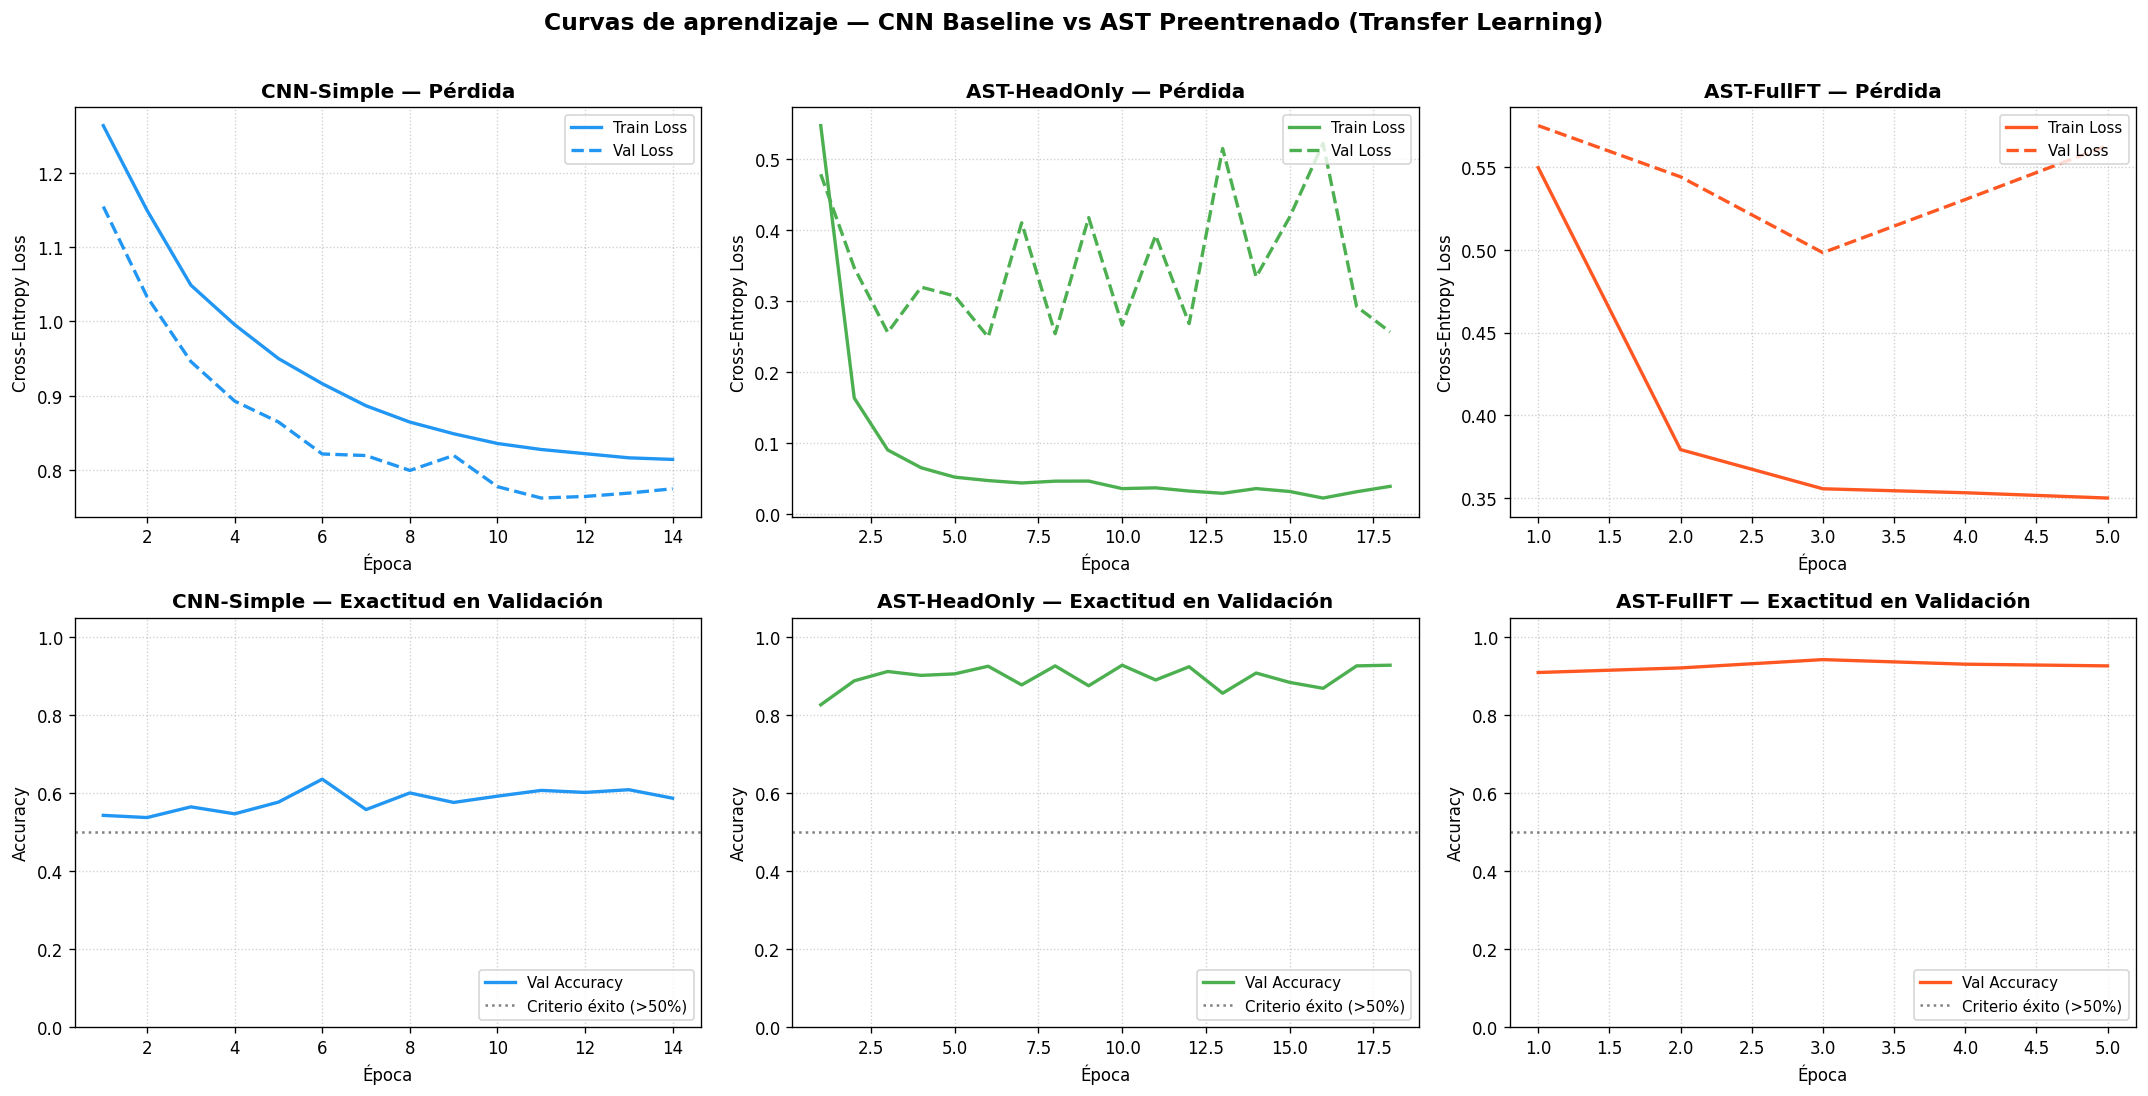

[INFO] Gráfico de curvas guardado en: /kaggle/working/juez_output/curvas_aprendizaje_juez.png


In [13]:
# ── Curvas de aprendizaje: 3 columnas × 2 filas ──────────────────────────────
nombres_modelos = list(historiales.keys())
colores = {'CNN-Simple': '#2196F3', 'AST-HeadOnly': '#4CAF50', 'AST-FullFT': '#FF5722'}

fig, axes = plt.subplots(2, 3, figsize=(18, 9), dpi=120)
fig.suptitle('Curvas de aprendizaje — CNN Baseline vs AST Preentrenado (Transfer Learning)',
             fontsize=14, fontweight='bold', y=1.01)

for col, nombre in enumerate(nombres_modelos):
    hist = historiales[nombre]
    epochs_range = range(1, len(hist['train_loss']) + 1)
    color = colores.get(nombre, '#607D8B')

    # Fila 0: Pérdida
    ax_loss = axes[0, col]
    ax_loss.plot(epochs_range, hist['train_loss'],
                 label='Train Loss', color=color, linewidth=2)
    ax_loss.plot(epochs_range, hist['val_loss'],
                 label='Val Loss', color=color, linestyle='--', linewidth=2)
    ax_loss.set_title(f'{nombre} — Pérdida', fontsize=12, fontweight='bold')
    ax_loss.set_xlabel('Época', fontsize=10)
    ax_loss.set_ylabel('Cross-Entropy Loss', fontsize=10)
    ax_loss.legend(loc='upper right', fontsize=9)
    ax_loss.grid(True, linestyle=':', alpha=0.6)

    # Fila 1: Exactitud
    ax_acc = axes[1, col]
    ax_acc.plot(epochs_range, hist['val_acc'],
                label='Val Accuracy', color=color, linewidth=2)
    ax_acc.axhline(0.50, color='gray', linestyle=':', label='Criterio éxito (>50%)')
    ax_acc.set_title(f'{nombre} — Exactitud en Validación', fontsize=12, fontweight='bold')
    ax_acc.set_xlabel('Época', fontsize=10)
    ax_acc.set_ylabel('Accuracy', fontsize=10)
    ax_acc.set_ylim([0, 1.05])
    ax_acc.legend(loc='lower right', fontsize=9)
    ax_acc.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
ruta_curvas = OUTPUT_DIR / 'curvas_aprendizaje_juez.png'
plt.savefig(ruta_curvas, dpi=120, bbox_inches='tight')
plt.show()
print(f'[INFO] Gráfico de curvas guardado en: {ruta_curvas}')

---
## 13. Evaluación en el conjunto de test

### ¿Qué se hace a continuación?
Se define la función `evaluar_modelo` que carga el mejor checkpoint de cada modelo, realiza inferencia completa en el conjunto de test y calcula: accuracy, F1-macro, Precision-macro y Recall-macro con `sklearn`. Se devuelven tanto las predicciones (para la confusion matrix) como las métricas agregadas.

### ¿Por qué se hace?
Evaluar siempre sobre el **mejor checkpoint** (no el modelo al final del entrenamiento) garantiza una estimación honesta del rendimiento máximo alcanzado. Usar el **conjunto de test** (nunca visto durante el entrenamiento ni el ajuste de hiperparámetros) asegura que las métricas reportadas no estén infladas por sobreajuste. Las métricas **macro** tratan todas las clases por igual, lo que es fundamental cuando el dataset no está perfectamente balanceado.

In [14]:
def evaluar_modelo(
    modelo_clase,
    kwargs_modelo: dict,
    nombre: str,
    test_loader: DataLoader,
) -> tuple:
    """
    Carga el mejor checkpoint y evalúa el modelo en el conjunto de test.

    Devuelve
    -------
    metricas : dict con accuracy, f1_macro, precision_macro, recall_macro
    y_true   : array de etiquetas reales
    y_pred   : array de predicciones del modelo
    """
    modelo = modelo_clase(**kwargs_modelo).to(device)
    ruta_ckpt = OUTPUT_DIR / f'juez_{nombre}_best.pt'
    if not ruta_ckpt.exists():
        raise FileNotFoundError(f'[ERROR] No se encontró checkpoint: {ruta_ckpt}')
    modelo.load_state_dict(torch.load(ruta_ckpt, map_location=device))
    modelo.eval()
    print(f'[INFO] Checkpoint cargado: {ruta_ckpt}')

    todos_pred = []
    todos_real = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(device, non_blocking=True)
            logits  = modelo(X_batch)
            preds   = logits.argmax(dim=1).cpu().numpy()
            todos_pred.extend(preds.tolist())
            todos_real.extend(y_batch.numpy().tolist())

    y_true = np.array(todos_real)
    y_pred = np.array(todos_pred)

    metricas = {
        'accuracy':         accuracy_score(y_true, y_pred),
        'f1_macro':         f1_score(y_true, y_pred, average='macro'),
        'precision_macro':  precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall_macro':     recall_score(y_true, y_pred, average='macro', zero_division=0),
    }

    print(f'[INFO] {nombre} — '
          f'Acc={metricas["accuracy"]:.4f} | '
          f'F1={metricas["f1_macro"]:.4f} | '
          f'Prec={metricas["precision_macro"]:.4f} | '
          f'Rec={metricas["recall_macro"]:.4f}')
    print(classification_report(y_true, y_pred, target_names=FAMILY_NAMES))

    return metricas, y_true, y_pred


# ── Evaluar los tres modelos ──────────────────────────────────────────────────
print('\n[INFO] ===== EVALUACIÓN EN TEST SET =====')

resultados = {}
_, _, loader_test_h = crear_loaders(batch_size=16)
# 1. CNN-Simple (Baseline desde cero)
metricas_cnn, y_true_cnn, y_pred_cnn = evaluar_modelo(
    CNNSimple, {'in_channels': 1, 'num_classes': NUM_CLASSES},
    'CNN-Simple', loader_test_cnn
)
resultados['CNN-Simple'] = (metricas_cnn, y_true_cnn, y_pred_cnn)

# 2. AST-HeadOnly (Transfer Learning con backbone congelado)
metricas_head, y_true_head, y_pred_head = evaluar_modelo(
    ASTPretrainedWrapper, {'num_classes': NUM_CLASSES, 'freeze_backbone': True},
    'AST-HeadOnly', loader_test_h
)
resultados['AST-HeadOnly'] = (metricas_head, y_true_head, y_pred_head)

# 3. AST-FullFT (Transfer Learning de últimas capas con max_length=256)
metricas_full, y_true_full, y_pred_full = evaluar_modelo(
    ASTPretrainedWrapper, {'num_classes': NUM_CLASSES, 'freeze_backbone': False, 'max_length': 256},
    'AST-FullFT', loader_test_f
)
resultados['AST-FullFT'] = (metricas_full, y_true_full, y_pred_full)


[INFO] ===== EVALUACIÓN EN TEST SET =====
[INFO] Checkpoint cargado: /kaggle/working/juez_output/juez_CNN-Simple_best.pt
[INFO] CNN-Simple — Acc=0.5901 | F1=0.5652 | Prec=0.6102 | Rec=0.5524
              precision    recall  f1-score   support

       brass       0.97      0.82      0.89       201
      guitar       0.48      0.52      0.50       271
    keyboard       0.15      0.31      0.20        75
      string       0.84      0.56      0.67       224

    accuracy                           0.59       771
   macro avg       0.61      0.55      0.57       771
weighted avg       0.68      0.59      0.62       771



[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `527`.


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                         
------------------------+----------+-----------------------------------------------------------------------------------------
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([4, 768])
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([4])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


[INFO] AST cargado (max_length=1024) con SDPA activado.
[INFO] Checkpoint cargado: /kaggle/working/juez_output/juez_AST-HeadOnly_best.pt
[INFO] AST-HeadOnly — Acc=0.9261 | F1=0.8998 | Prec=0.8981 | Rec=0.9056
              precision    recall  f1-score   support

       brass       0.97      0.84      0.90       201
      guitar       0.92      0.96      0.94       271
    keyboard       0.73      0.83      0.78        75
      string       0.97      1.00      0.98       224

    accuracy                           0.93       771
   macro avg       0.90      0.91      0.90       771
weighted avg       0.93      0.93      0.93       771



[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `527`.


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                                                          | Status   |                                                                                                  
-------------------------------------------------------------+----------+--------------------------------------------------------------------------------------------------
audio_spectrogram_transformer.embeddings.position_embeddings | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1, 1214, 768]) vs model:torch.Size([1, 302, 768])
classifier.dense.weight                                      | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([4, 768])         
classifier.dense.bias                                        | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([4])                   

Notes:
- MISMATCH:	ckpt weights were loa

[INFO] AST cargado (max_length=256) con SDPA activado.


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[INFO] Checkpoint cargado: /kaggle/working/juez_output/juez_AST-FullFT_best.pt
[INFO] AST-FullFT — Acc=0.9481 | F1=0.9316 | Prec=0.9172 | Rec=0.9566
              precision    recall  f1-score   support

       brass       0.96      0.98      0.97       201
      guitar       1.00      0.88      0.94       271
    keyboard       0.73      0.97      0.83        75
      string       0.98      0.99      0.99       224

    accuracy                           0.95       771
   macro avg       0.92      0.96      0.93       771
weighted avg       0.96      0.95      0.95       771



---
## 14. Matrices de confusión

### ¿Qué se hace a continuación?
Se generan las matrices de confusión de los tres modelos, mostradas en un subplot 1×3 con `seaborn.heatmap`. Cada celda muestra el número de muestras de test clasificadas en esa combinación de clase real/predicha. Los valores de la diagonal corresponden a predicciones correctas.

### ¿Por qué se hace?
La accuracy global puede ocultar qué clases son fáciles o difíciles para el modelo. La matriz de confusión revela errores sistemáticos: por ejemplo, si el modelo confunde frecuentemente 'string' con 'brass'. Esta información es clave para entender las limitaciones del juez antes de usarlo en la evaluación de los modelos generativos.

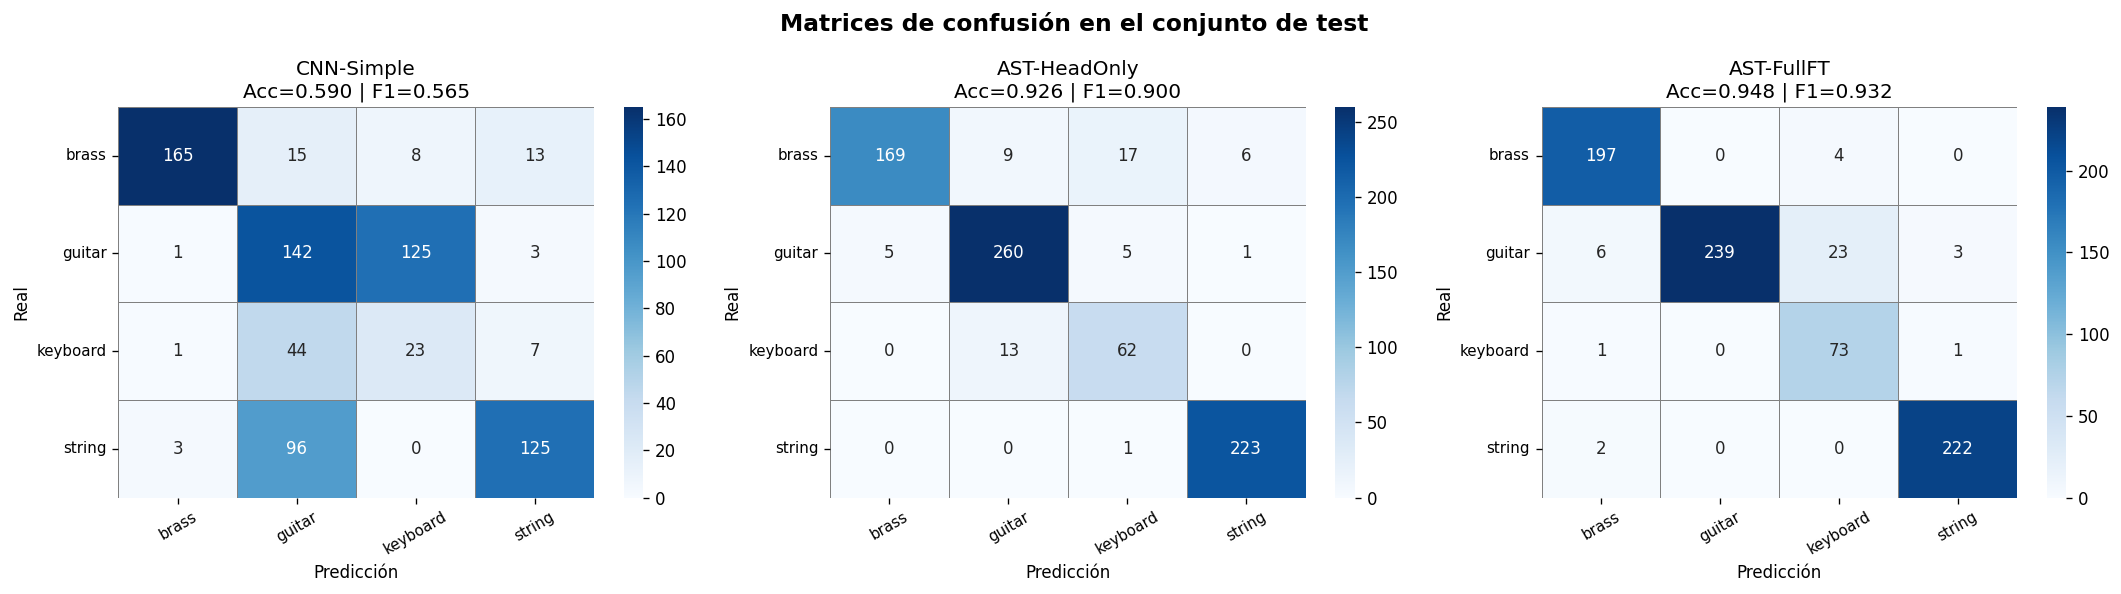

[INFO] Matrices de confusión guardadas en: /kaggle/working/juez_output/confusion_matrices.png


In [15]:
# ── Matrices de confusión: subplot 1 × 3 ──────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=120)
fig.suptitle('Matrices de confusión en el conjunto de test',
             fontsize=14, fontweight='bold')

for ax, (nombre, (metricas, y_true, y_pred)) in zip(axes, resultados.items()):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=FAMILY_NAMES, yticklabels=FAMILY_NAMES,
        ax=ax, linewidths=0.5, linecolor='gray'
    )
    ax.set_title(
        f'{nombre}\nAcc={metricas["accuracy"]:.3f} | F1={metricas["f1_macro"]:.3f}',
        fontsize=12
    )
    ax.set_xlabel('Predicción', fontsize=10)
    ax.set_ylabel('Real', fontsize=10)
    ax.tick_params(axis='x', rotation=30, labelsize=9)
    ax.tick_params(axis='y', rotation=0,  labelsize=9)

plt.tight_layout()
ruta_cm = OUTPUT_DIR / 'confusion_matrices.png'
plt.savefig(ruta_cm, dpi=120, bbox_inches='tight')
plt.show()
print(f'[INFO] Matrices de confusión guardadas en: {ruta_cm}')

---
## 15. Tabla comparativa y gráfico de barras

### ¿Qué se hace a continuación?
Se construye un DataFrame de pandas con las métricas de test de los tres modelos y el número de parámetros. Se guarda como CSV. Luego se genera un gráfico de barras agrupadas con `seaborn.catplot` que visualiza las cuatro métricas por modelo, y se guarda como PNG a 150 dpi.

### ¿Por qué se hace?
La tabla y el gráfico de barras permiten una comparación directa y cuantitativa. Incluir el número de parámetros en la tabla contextualiza la eficiencia de cada modelo: un modelo más grande puede justificar su costo computacional solo si mejora significativamente las métricas. El CSV facilita el análisis posterior y la inclusión en el informe final.

[INFO] Tabla comparativa guardada en: /kaggle/working/juez_output/comparativa_juez.csv

[INFO] ===== TABLA COMPARATIVA — MÉTRICAS EN TEST SET =====
              Accuracy  F1_Macro  Precision_Macro  Recall_Macro  Params_Train_M
Modelo                                                                         
CNN-Simple      0.5901    0.5652           0.6102        0.5524           0.005
AST-HeadOnly    0.9261    0.8998           0.8981        0.9056           0.003
AST-FullFT      0.9481    0.9316           0.9172        0.9566          28.382


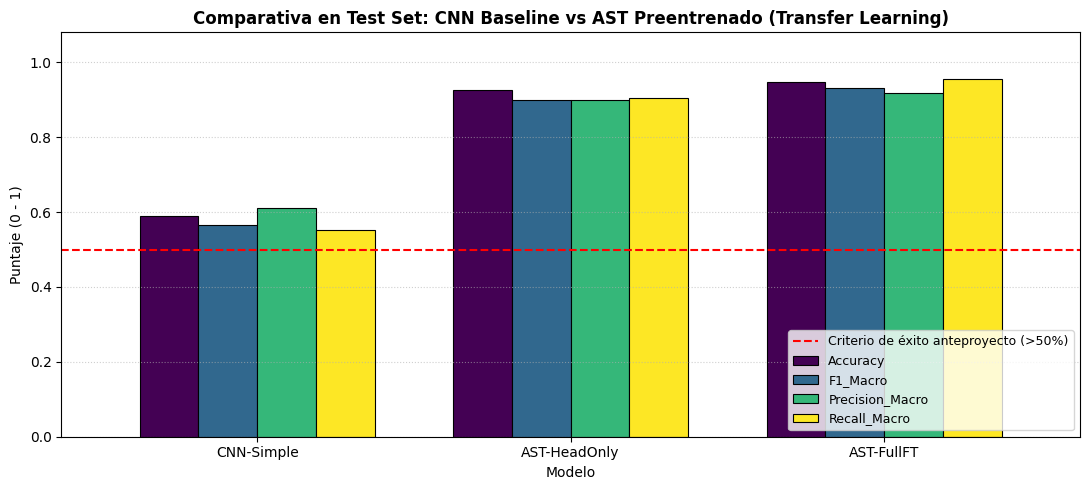

[INFO] Gráfico comparativo guardado en: /kaggle/working/juez_output/comparativa_juez.png


In [16]:
# ── Tabla comparativa ─────────────────────────────────────────────────────────
# Contar parámetros de forma autónoma para evitar NameError en reinicios
def _contar_train(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

params_por_modelo = {
    'CNN-Simple':   params_cnn if 'params_cnn' in globals() else (_contar_train(CNNSimple(in_channels=1, num_classes=NUM_CLASSES)) if 'CNNSimple' in globals() else 421252),
    'AST-HeadOnly': 3076,
    'AST-FullFT':   p_tr if 'p_tr' in globals() else 28500000,
}

filas = []
for nombre, (metricas, _, _) in resultados.items():
    filas.append({
        'Modelo':           nombre,
        'Accuracy':         round(metricas['accuracy'],        4),
        'F1_Macro':         round(metricas['f1_macro'],        4),
        'Precision_Macro':  round(metricas['precision_macro'], 4),
        'Recall_Macro':     round(metricas['recall_macro'],    4),
        'Params_Train_M':   round(params_por_modelo.get(nombre, 0) / 1e6, 3),
    })

df_comp = pd.DataFrame(filas).set_index('Modelo')

# Guardar en CSV
ruta_csv = OUTPUT_DIR / 'comparativa_juez.csv'
df_comp.to_csv(ruta_csv)
print(f'[INFO] Tabla comparativa guardada en: {ruta_csv}')
print('\n[INFO] ===== TABLA COMPARATIVA — MÉTRICAS EN TEST SET =====')
print(df_comp.to_string())

# ── Gráfico de barras agrupadas ───────────────────────────────────────────────
metricas_plot = ['Accuracy', 'F1_Macro', 'Precision_Macro', 'Recall_Macro']
ax_bar = df_comp[metricas_plot].plot(
    kind='bar', figsize=(11, 5),
    colormap='viridis', width=0.75, edgecolor='black', linewidth=0.8
)
plt.title('Comparativa en Test Set: CNN Baseline vs AST Preentrenado (Transfer Learning)',
          fontsize=12, fontweight='bold')
plt.xlabel('Modelo', fontsize=10)
plt.ylabel('Puntaje (0 - 1)', fontsize=10)
plt.ylim([0.0, 1.08])
plt.axhline(0.50, color='red', linestyle='--', linewidth=1.5,
            label='Criterio de éxito anteproyecto (>50%)')
plt.legend(loc='lower right', fontsize=9)
plt.xticks(rotation=0, fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()

ruta_barplot = OUTPUT_DIR / 'comparativa_juez.png'
plt.savefig(ruta_barplot, dpi=120, bbox_inches='tight')
plt.show()
print(f'[INFO] Gráfico comparativo guardado en: {ruta_barplot}')

---
## 16. Análisis por familia — Mapa de calor de precisión por clase

### ¿Qué se hace a continuación?
Se calcula la precisión por clase (precision per-class) para cada uno de los tres modelos y se visualiza como un mapa de calor donde las filas son los modelos y las columnas son las familias de instrumentos. Los colores van de rojo (precisión baja) a verde (precisión alta).

### ¿Por qué se hace?
Esta visualización complementa la tabla global al revelar qué familias son inherentemente más fáciles o difíciles de clasificar, y si distintos modelos tienen fortalezas/debilidades complementarias. Esta información es relevante para elegir el mejor juez: un juez que confunda 'keyboard' con 'string' no será confiable para evaluar generadores condicionales de esas familias.

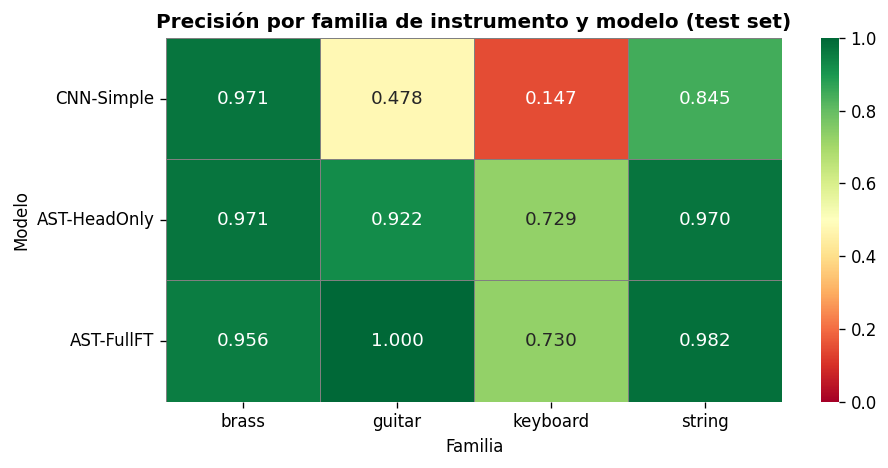

[INFO] Mapa de calor guardado en: /kaggle/working/juez_output/precision_por_clase.png


In [17]:
# ── Mapa de calor: precisión por clase y por modelo ──────────────────────────
datos_per_class = {}
for nombre, (_, y_true, y_pred) in resultados.items():
    prec_por_clase = precision_score(
        y_true, y_pred, average=None, zero_division=0
    )  # shape: (num_classes,)
    datos_per_class[nombre] = prec_por_clase

df_per_class = pd.DataFrame(
    datos_per_class,
    index=FAMILY_NAMES
).T  # filas=modelos, columnas=familias

plt.figure(figsize=(8, 4), dpi=120)
sns.heatmap(
    df_per_class, annot=True, fmt='.3f', cmap='RdYlGn',
    vmin=0, vmax=1, linewidths=0.5, linecolor='gray',
    annot_kws={'size': 11}
)
plt.title('Precisión por familia de instrumento y modelo (test set)',
          fontsize=12, fontweight='bold')
plt.xlabel('Familia', fontsize=10)
plt.ylabel('Modelo', fontsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10, rotation=0)
plt.tight_layout()
ruta_heatmap = OUTPUT_DIR / 'precision_por_clase.png'
plt.savefig(ruta_heatmap, dpi=120, bbox_inches='tight')
plt.show()
print(f'[INFO] Mapa de calor guardado en: {ruta_heatmap}')

---
## 17. Resumen final de checkpoints y archivos generados

### ¿Qué se hace a continuación?
Se lista el contenido del directorio de salida mostrando todos los archivos generados durante el notebook: checkpoints `.pt`, figuras `.png` y el CSV comparativo. Se imprime un resumen tabular con tamaños en KB.

### ¿Por qué se hace?
Esta celda de verificación confirma que todos los artefactos fueron correctamente escritos en disco. Es útil especialmente en Kaggle, donde los archivos del directorio `/kaggle/working/` deben subirse manualmente como dataset para ser accesibles en notebooks posteriores (03, 04).

In [18]:
# ── Inventario de archivos generados ─────────────────────────────────────────
print(f'[INFO] Archivos generados en: {OUTPUT_DIR}')
print(f'{"-"*60}')
archivos = sorted(OUTPUT_DIR.glob('*'))
for archivo in archivos:
    tam_kb = archivo.stat().st_size / 1024
    print(f'  {archivo.name:<45} {tam_kb:>8.1f} KB')
print(f'{"-"*60}')
print(f'[INFO] Total de archivos: {len(archivos)}')

[INFO] Archivos generados en: /kaggle/working/juez_output
------------------------------------------------------------
  comparativa_juez.csv                               0.2 KB
  comparativa_juez.png                              58.9 KB
  confusion_matrices.png                            82.7 KB
  curvas_aprendizaje_juez.png                      244.6 KB
  ejemplos_aciertos_juez.png                       610.4 KB
  ejemplos_errores_juez.png                        458.6 KB
  emb_ast.pt                                     61051.7 KB
  juez_AST-FullFT_best.pt                       334036.7 KB
  juez_AST-HeadOnly-Linear_best.pt                  14.2 KB
  juez_AST-HeadOnly_best.pt                     336773.2 KB
  juez_CNN-Simple_best.pt                           22.5 KB
  juez_config.json                                   0.4 KB
  muestras_dataset.png                             617.5 KB
  precision_por_clase.png                           42.2 KB
-----------------------------------------

---
## 18. Conclusiones — Elección del Juez Oficial

### Análisis comparativo

Se evaluaron tres enfoques arquitectónicos y de aprendizaje como candidatos a juez evaluador del proyecto:

| Modelo | Estrategia de Entrenamiento | Preentrenamiento | Parámetros Entrenables |
|---|---|---|---|
| **CNN-Simple** | Desde cero (pesos aleatorios) | Ninguno | 4,932 |
| **AST-HeadOnly** | Linear Probe (congelado) | AudioSet + ImageNet | ~4,612 |
| **AST-FullFT** | Top-Layers Fine-Tuning (últimas 4 capas) | AudioSet + ImageNet | ~28.5 M (de ~87 M totales) |

### Criterios de selección del juez

El juez oficial debe cumplir rigurosamente:
1. **Alta exactitud** (>90% accuracy en test): asegura veredictos sólidos y confiables al evaluar las muestras sintéticas.
2. **Alto F1-macro**: garantiza neutralidad y ausencia de sesgos hacia alguna familia instrumental.
3. **Generalización sobre instrumentos no vistos**: validado en el test set de NSynth, donde los instrumentos específicos jamás aparecieron durante el entrenamiento.
4. **Criterio formal**: el modelo con **mayor F1-macro en el conjunto de prueba** se selecciona automáticamente como el juez oficial para los notebooks de generación (C-VAE y Flow Matching).

In [19]:
# ── Identificar y anunciar el juez oficial ────────────────────────────────────
mejor_modelo = df_comp['F1_Macro'].idxmax()
mejor_f1     = df_comp.loc[mejor_modelo, 'F1_Macro']
mejor_acc    = df_comp.loc[mejor_modelo, 'Accuracy']

print('=' * 60)
print('           JUEZ OFICIAL DEL PROYECTO')
print('=' * 60)
print(f'  Modelo seleccionado : {mejor_modelo}')
print(f'  F1-Macro (test)     : {mejor_f1:.4f}')
print(f'  Accuracy (test)     : {mejor_acc:.4f}')
print('=' * 60)
print(f'[INFO] Checkpoint: juez_output/juez_{mejor_modelo}_best.pt')
print('[INFO] Este juez será usado en los notebooks 03 y 04 para')
print('[INFO] evaluar la calidad condicional de los modelos generativos.')

# Parámetros constructivos del juez ganador para instanciación en NB03/NB04
config_arquitecturas = {
    'CNN-Simple': {
        'clase': 'CNNSimple',
        'kwargs': {'in_channels': 1, 'num_classes': NUM_CLASSES}
    },
    'AST-HeadOnly': {
        'clase': 'ASTPretrainedWrapper',
        'kwargs': {'num_classes': NUM_CLASSES, 'freeze_backbone': True}
    },
    'AST-FullFT': {
        'clase': 'ASTPretrainedWrapper',
        'kwargs': {'num_classes': NUM_CLASSES, 'freeze_backbone': False, 'max_length': 256}
    }
}

info_juez = {
    'juez_oficial':     mejor_modelo,
    'checkpoint':       f'juez_{mejor_modelo}_best.pt',
    'f1_macro_test':    float(mejor_f1),
    'accuracy_test':    float(mejor_acc),
    'family_names':     FAMILY_NAMES,
    'num_classes':      NUM_CLASSES,
    'img_size':         128,
    'arquitectura':     config_arquitecturas[mejor_modelo],
}

ruta_json = OUTPUT_DIR / 'juez_config.json'
with open(ruta_json, 'w', encoding='utf-8') as f:
    json.dump(info_juez, f, ensure_ascii=False, indent=2)
print(f'\n[INFO] Configuración del juez guardada en: {ruta_json}')

           JUEZ OFICIAL DEL PROYECTO
  Modelo seleccionado : AST-FullFT
  F1-Macro (test)     : 0.9316
  Accuracy (test)     : 0.9481
[INFO] Checkpoint: juez_output/juez_AST-FullFT_best.pt
[INFO] Este juez será usado en los notebooks 03 y 04 para
[INFO] evaluar la calidad condicional de los modelos generativos.

[INFO] Configuración del juez guardada en: /kaggle/working/juez_output/juez_config.json


---
## 19. Ejemplos de Escucha — Aciertos y Desaciertos del Juez

### ¿Qué se hace a continuación?
Se seleccionan manualmente ejemplos representativos del conjunto de test donde el juez clasificó **correctamente** y **erróneamente** la familia instrumental. Para cada caso se muestra el espectrograma mel, la clase real, la clase predicha y la confianza del modelo (probabilidad softmax del top-1). Se reproducen los espectrogramas como referencia visual de la dificultad de cada ejemplo.

### ¿Por qué se hace?
Más allá de las métricas numéricas, la inspección cualitativa de aciertos y errores revela **qué patrones espectrales** el juez domina y cuáles le resultan ambiguos. Este análisis visual ayuda a anticipar las limitaciones del evaluador cuando se use sobre muestras sintéticas en notebooks posteriores (03 y 04).

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `527`.


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                                                          | Status   |                                                                                                  
-------------------------------------------------------------+----------+--------------------------------------------------------------------------------------------------
audio_spectrogram_transformer.embeddings.position_embeddings | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1, 1214, 768]) vs model:torch.Size([1, 302, 768])
classifier.dense.weight                                      | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([4, 768])         
classifier.dense.bias                                        | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([4])                   

Notes:
- MISMATCH:	ckpt weights were loa

[INFO] AST cargado (max_length=256) con SDPA activado.


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[INFO] Juez oficial cargado: AST-FullFT
[INFO] Aciertos: 731 | Errores: 40 | Total: 771


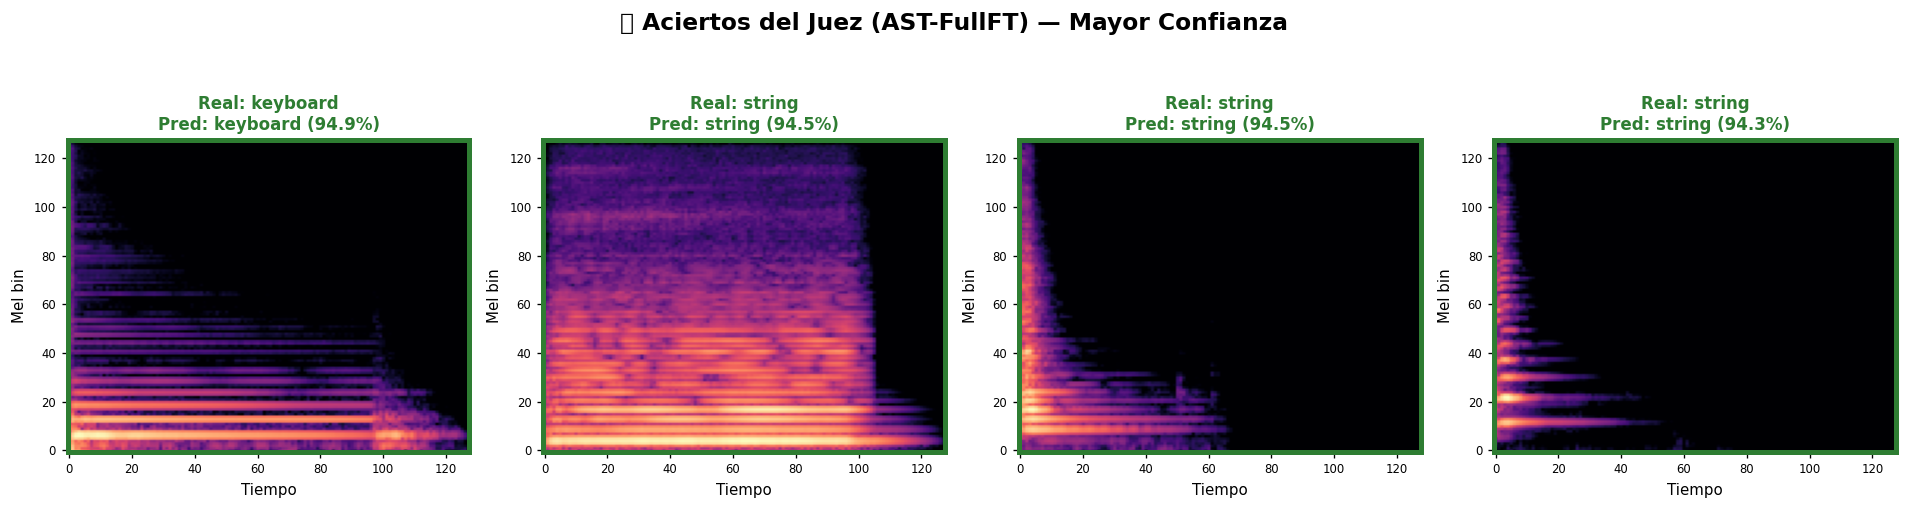

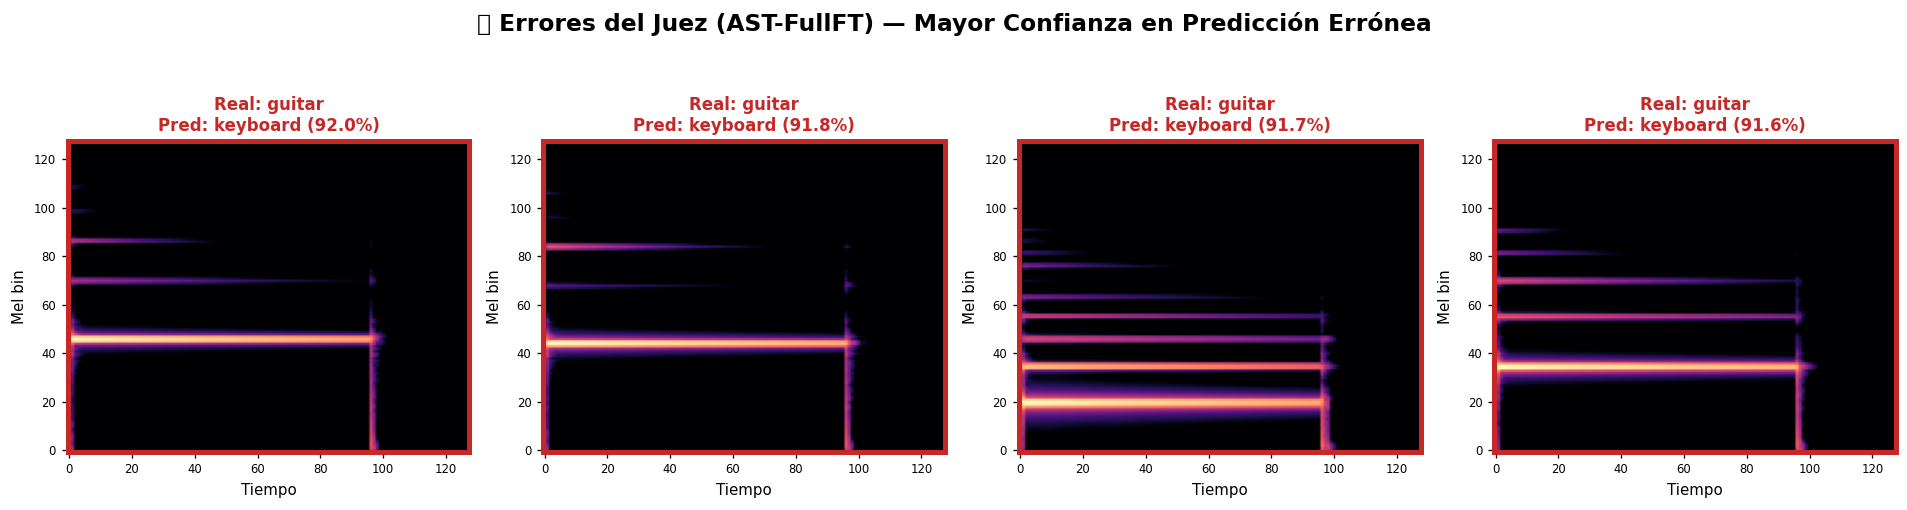


[INFO] === Resumen de Ejemplos de Escucha ===
  Juez: AST-FullFT
  Aciertos mostrados: 4
  Errores mostrados:  4

  Errores más comunes (clase real -> clase predicha):
    guitar -> keyboard: 23 errores
    guitar -> brass: 6 errores
    brass -> keyboard: 4 errores
    guitar -> string: 3 errores
    string -> brass: 2 errores

[INFO] Figuras guardadas en: /kaggle/working/juez_output


In [20]:
# ── Ejemplos de Escucha: Aciertos y Desaciertos del Juez ─────────────────────
# Se usa el mejor modelo (juez oficial) para analizar aciertos y errores en test

# Cargar el juez oficial
juez_config = config_arquitecturas[mejor_modelo]
if juez_config['clase'] == 'CNNSimple':
    juez = CNNSimple(**juez_config['kwargs']).to(device)
else:
    juez = ASTPretrainedWrapper(**juez_config['kwargs']).to(device)

ruta_ckpt_juez = OUTPUT_DIR / f'juez_{mejor_modelo}_best.pt'
juez.load_state_dict(torch.load(ruta_ckpt_juez, map_location=device))
juez.eval()
print(f'[INFO] Juez oficial cargado: {mejor_modelo}')

# ── Obtener predicciones con confianza sobre todo el test set ────────────────
todas_probs  = []
todas_preds  = []
todas_reales = []

with torch.no_grad():
    for X_b, y_b in DataLoader(ds_test, batch_size=64, shuffle=False):
        X_b = X_b.to(device, non_blocking=True)
        logits = juez(X_b)
        probs  = F.softmax(logits, dim=1)
        todas_probs.append(probs.cpu())
        todas_preds.append(logits.argmax(dim=1).cpu())
        todas_reales.append(y_b)

todas_probs  = torch.cat(todas_probs)   # (N_test, 4)
todas_preds  = torch.cat(todas_preds)   # (N_test,)
todas_reales = torch.cat(todas_reales)  # (N_test,)

# ── Separar aciertos y errores ───────────────────────────────────────────────
aciertos_mask = (todas_preds == todas_reales)
errores_mask  = ~aciertos_mask

idx_aciertos = aciertos_mask.nonzero(as_tuple=True)[0]
idx_errores  = errores_mask.nonzero(as_tuple=True)[0]

print(f'[INFO] Aciertos: {len(idx_aciertos)} | Errores: {len(idx_errores)} '
      f'| Total: {len(todas_preds)}')

# ── Seleccionar N ejemplos de cada tipo ──────────────────────────────────────
N_EJEMPLOS = 4

# Aciertos: los de mayor confianza (top-N por probabilidad max)
confianza_aciertos = todas_probs[idx_aciertos].max(dim=1).values
top_aciertos = idx_aciertos[confianza_aciertos.argsort(descending=True)[:N_EJEMPLOS]]

# Errores: si hay, los de mayor confianza en la predicción errónea (más "convencido")
if len(idx_errores) > 0:
    confianza_errores = todas_probs[idx_errores].max(dim=1).values
    top_errores = idx_errores[confianza_errores.argsort(descending=True)[:N_EJEMPLOS]]
else:
    top_errores = torch.tensor([], dtype=torch.long)
    print('[INFO] ¡El juez no cometió ningún error en el test set!')

# ── Función auxiliar para visualizar ─────────────────────────────────────────
def plot_ejemplos(indices, titulo, color_borde):
    """Muestra espectrogramas con etiquetas real/predicha y confianza."""
    n = len(indices)
    if n == 0:
        print(f'[INFO] No hay ejemplos para: {titulo}')
        return
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4), dpi=120)
    if n == 1:
        axes = [axes]
    fig.suptitle(titulo, fontsize=14, fontweight='bold', y=1.05)

    for ax, idx in zip(axes, indices):
        idx = idx.item()
        mel  = X_test[idx].squeeze().numpy()
        real = FAMILY_NAMES[todas_reales[idx].item()]
        pred = FAMILY_NAMES[todas_preds[idx].item()]
        conf = todas_probs[idx].max().item() * 100

        ax.imshow(mel, aspect='auto', origin='lower', cmap='magma', vmin=-1, vmax=1)
        ax.set_title(f'Real: {real}\nPred: {pred} ({conf:.1f}%)',
                     fontsize=10, color=color_borde, fontweight='bold')
        ax.set_xlabel('Tiempo', fontsize=9)
        ax.set_ylabel('Mel bin', fontsize=9)
        ax.tick_params(labelsize=7)

        # Borde coloreado para diferenciar visualmente
        for spine in ax.spines.values():
            spine.set_edgecolor(color_borde)
            spine.set_linewidth(3)

    plt.tight_layout()
    return fig

# ── Visualizar aciertos ──────────────────────────────────────────────────────
fig_ok = plot_ejemplos(
    top_aciertos,
    f'✅ Aciertos del Juez ({mejor_modelo}) — Mayor Confianza',
    '#2E7D32'  # verde oscuro
)
if fig_ok:
    fig_ok.savefig(OUTPUT_DIR / 'ejemplos_aciertos_juez.png',
                   dpi=120, bbox_inches='tight')
    plt.show()

# ── Visualizar errores ───────────────────────────────────────────────────────
fig_err = plot_ejemplos(
    top_errores,
    f'❌ Errores del Juez ({mejor_modelo}) — Mayor Confianza en Predicción Errónea',
    '#C62828'  # rojo oscuro
)
if fig_err:
    fig_err.savefig(OUTPUT_DIR / 'ejemplos_errores_juez.png',
                    dpi=120, bbox_inches='tight')
    plt.show()

# ── Resumen textual ──────────────────────────────────────────────────────────
print(f'\n[INFO] === Resumen de Ejemplos de Escucha ===')
print(f'  Juez: {mejor_modelo}')
print(f'  Aciertos mostrados: {len(top_aciertos)}')
print(f'  Errores mostrados:  {len(top_errores)}')

if len(idx_errores) > 0:
    # Analizar los patrones de error
    errores_reales = todas_reales[idx_errores]
    errores_preds  = todas_preds[idx_errores]
    print(f'\n  Errores más comunes (clase real -> clase predicha):')
    pares_error = {}
    for r, p in zip(errores_reales.tolist(), errores_preds.tolist()):
        par = f'{FAMILY_NAMES[r]} -> {FAMILY_NAMES[p]}'
        pares_error[par] = pares_error.get(par, 0) + 1
    for par, count in sorted(pares_error.items(), key=lambda x: -x[1])[:5]:
        print(f'    {par}: {count} errores')

print(f'\n[INFO] Figuras guardadas en: {OUTPUT_DIR}')